# Assignment 11: Spatial community composition — blobs or stripes?

### **This is an imaginary exercise.**

Maine can protect **1,000 km²** as two compact **blob** parks or two long,
narrow **stripe** parks. Each park covers 500 km². Which design would you
recommend for conserving amphibian diversity?

Follow the analyses in [Lab10](../labs/Lab10-CommunityComposition.ipynb), now
comparing park shapes. You may reuse its code and functions. Complete the code cells 
and short answers. Submit this notebook with its maps, tables, and saved summary CSVs.

## The data

[`ME_BlobStripeParks.geojson`](../data/ME_BlobStripeParks.geojson) contains two
roughly round blobs and two elliptical stripes, five times as long as they
are wide. All four are imaginary, nonoverlapping, and within Maine and the
source sample bounds. Each point already has a park assignment.

Sampling follows Lab10. All real records inside these parks are retained.
All source records in `amphibians.geojson` determine each observed species'
convex hull, its 50 km buffer, and its record-count weight. Each of **50 invented
species** inherits the buffered range and abundance weight of a randomly
sampled observed species. Added points are sampled within those ranges'
intersections with the parks, with counts proportional to the observed or
inherited weights. One point per invented species is reserved. There are
**1,500 total points**, including originals; seed = 597.

`synthetic` identifies generated points; `imaginary_species` identifies invented
taxa.

## 1. Import packages and load the data

Run from `docs/assignments` using the same environment as Lab10.

In [28]:
from pathlib import Path

import geopandas as gpd
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import entropy
from scipy.spatial.distance import jaccard, braycurtis

AREA_CRS = "EPSG:5070"
COLORS = {"blob": "forestgreen", "stripe": "darkorange"}
designs = ["blob", "stripe"]

In [40]:
features = gpd.read_file("../data/ME_BlobStripeParks.geojson")
parks = features[features.feature_type == "park"].copy()
parks = parks.to_crs(AREA_CRS).set_index("park_id")
records = features[features.feature_type == "occurrence"].copy().to_crs(AREA_CRS)
park_order = list(parks.index)

display(parks[["park_name", "scenario", "area_km2"]])
print("Total occurrence records:", len(records))

,park_name,scenario,area_km2
park_id,,,
B1,Alder Crown Preserve,blob,500.0
B2,Hemlock Hollow Reserve,blob,500.0
S1,Fern Ribbon Preserve,stripe,500.0
S2,Silver Brook Reach,stripe,500.0


Total occurrence records: 1500


## 2. Map the parks and check the comparison

Map the four polygons and their points, using one color per design. Label the
park IDs. A simple map is enough.

Calculate area in km² and show the total area and number of occurrence records
for each design. Keep all records, including generated points and invented
species, in the analyses below.

,measured_km2
scenario,
blob,1000.000589
stripe,1000.000753


,n_records
scenario,
blob,845
stripe,655


,n_records
polygon,
B1,436
B2,409
S1,328
S2,327


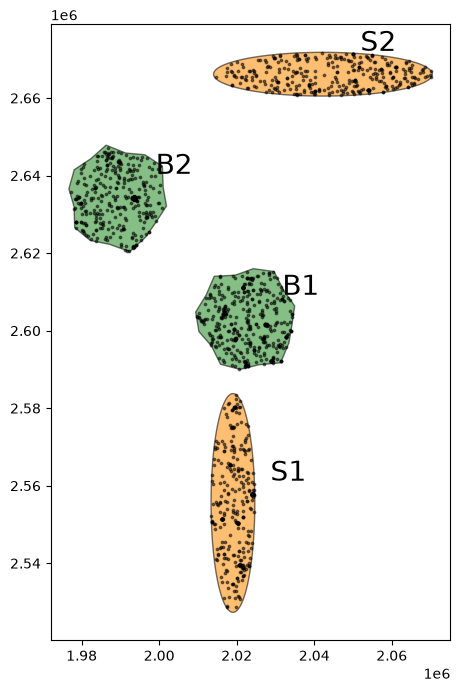

In [54]:
parks["measured_km2"] = parks.area / 1e6
display(parks.groupby("scenario")[["measured_km2"]].sum())

# Record counts per scenario
display(records.groupby("scenario").size().to_frame("n_records"))

# Record counts per polygon
points = records.to_crs(parks.crs)
polygons = parks[["scenario", "geometry"]].rename_axis("polygon").reset_index()

matches = gpd.sjoin(
    points[["scenario", "geometry"]],
    polygons,
    how="inner",
    predicate="within",
)
matches = matches[matches["scenario_left"] == matches["scenario_right"]]

counts = matches.groupby("polygon").size().reindex(parks.index, fill_value=0)
display(counts.rename_axis("polygon").to_frame("n_records"))

# Plot the parks and points, with the polygon row names as labels
fig, ax = plt.subplots(figsize=(8, 8))

for strategy, group in parks.groupby("scenario"):
    group.plot(ax=ax, color=COLORS[strategy], alpha=0.55, edgecolor="black")

points.plot(ax=ax, color="black", markersize=3, alpha=0.5)

for row in parks.itertuples():
    anchor = row.geometry.representative_point()
    ax.annotate(
        str(row.Index),
        xy=(anchor.x, anchor.y),
        xytext=(27, 17),
        textcoords="offset points",
        fontsize=20,
        color = 'k'
    )

plt.show()

**Interpretation:** What is held equal between the designs? What differs besides
shape? Predict which design will capture more species, and explain why.

*Your answer:* Area is held equal, number of records differs between shape. I think blobs will have more species as it has more occurences

## 3. Build the community matrix

Rows are parks; columns are species; entries are record counts. A zero means
no records of that species in that park. It does not establish true absence.

In [55]:
community = pd.crosstab(records.park_id, records.species)
community = community.reindex(park_order, fill_value=0)
presence = community > 0

display(community)

species,Ambystoma laterale,Ambystoma maculatum,Anaxyrus americanus,Aquarana clamitans,Aquarana septentrionalis,Boreorana sylvatica,Desmognathus fuscus,Dryophytes versicolor,Eurycea bislineata,Fictotriton alderi,...,Sylvophantoma glacialina,Sylvophantoma hazelii,Sylvophantoma inverna,Sylvophantoma kettleii,Sylvophantoma lichenosa,Sylvophantoma mapleii,Sylvophantoma noctiluca,Sylvophantoma sprucea,Sylvophantoma willowii,Sylvophantoma zephyra
park_id,,,,,,,,,,,,,,,,,,,,,
B1,1,15,47,38,0,37,0,21,1,0,...,0,0,0,3,4,2,1,0,0,8
B2,1,17,39,21,0,26,3,11,5,0,...,0,0,1,5,5,8,0,1,1,5
S1,0,5,47,18,0,22,3,18,6,0,...,1,0,0,2,3,2,0,0,1,5
S2,1,7,11,19,1,13,0,11,4,1,...,0,1,0,3,10,5,1,1,0,8


In [58]:
print('Richness:',len(community.columns))

Richness: 67


How many species occur in the whole dataset? Choose one species and describe
its distribution among the four parks using its column in `community`.

*Your answer:* 67 species occur across all communities. Ambystoma occurs more in B1 and B2, and less in the stripes. 

## 4. Richness, Shannon diversity, and evenness

Use the lab's function below. Shannon uses `scipy.stats.entropy`; larger values
reflect more species, greater evenness, or both.

In [59]:
def diversity(community_counts):
    results = pd.DataFrame(
        index=community_counts.index,
        columns=["n_records", "richness", "shannon"],
        dtype=float,
    )
    for unit, counts in community_counts.iterrows():
        species_present = counts[counts > 0]
        results.loc[unit, "n_records"] = counts.sum()
        if len(species_present) == 0:
            continue
        results.loc[unit, "richness"] = len(species_present)
        results.loc[unit, "shannon"] = entropy(species_present)
    return results

,n_records,richness,shannon,evenness,park_name,scenario
park_id,,,,,,
B1,436.0,51.0,3.323911,0.544485,Alder Crown Preserve,blob
B2,409.0,54.0,3.516299,0.623327,Hemlock Hollow Reserve,blob
S1,328.0,49.0,3.320299,0.564666,Fern Ribbon Preserve,stripe
S2,327.0,57.0,3.711955,0.718136,Silver Brook Reach,stripe


Text(0, 0.5, 'richness')

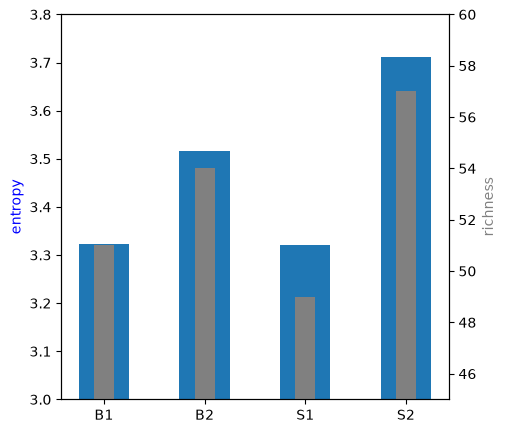

In [83]:
# Calculate park_metrics = diversity(community).
park_metrics = diversity(community)
# Add park names and scenarios from parks.
# Add evenness = np.exp(shannon) / richness, as in Lab10.
# Display the table and make a simple richness or Shannon plot.
park_metrics["evenness"] = np.exp(park_metrics["shannon"])/park_metrics["richness"]
park_metrics["park_name"] = parks.park_name
park_metrics["scenario"] = parks.scenario
display(park_metrics)

fig, ax = plt.subplots(figsize =(5,5))
ax.bar(park_metrics.index, park_metrics.shannon, width = 0.5)
ax.set_ylim(3,3.8)
ax.set_ylabel('entropy', color = 'b')
ax2 = ax.twinx()
ax2.bar(park_metrics.index, park_metrics.richness, width = 0.2, color = 'gray')
ax2.set_ylim(45,60)
ax2.set_ylabel('richness', color = 'gray')

Does the richest park also have the highest Shannon diversity and evenness?
What would adding 100 records of an already common species do to these measures?

*Your answer:* The richest park has the highest diversity and eveness. Adding 100 records would lower diversity and eveness. 

## 5. Alpha, beta, and gamma diversity

Pool the two blob parks, then the two stripe parks. For each design, calculate:

- **Alpha:** mean richness of its two parks.
- **Gamma:** richness in the pooled species list.
- **Multiplicative beta:** gamma divided by alpha.
- Total records and pooled Shannon diversity.

Keep the park rows in `community`; use `design_counts` for the pooled rows.

In [86]:
design_counts.head()

species,Ambystoma laterale,Ambystoma maculatum,Anaxyrus americanus,Aquarana clamitans,Aquarana septentrionalis,Boreorana sylvatica,Desmognathus fuscus,Dryophytes versicolor,Eurycea bislineata,Fictotriton alderi,...,Sylvophantoma glacialina,Sylvophantoma hazelii,Sylvophantoma inverna,Sylvophantoma kettleii,Sylvophantoma lichenosa,Sylvophantoma mapleii,Sylvophantoma noctiluca,Sylvophantoma sprucea,Sylvophantoma willowii,Sylvophantoma zephyra
blob,2.0,32.0,86.0,59.0,0.0,63.0,3.0,32.0,6.0,0.0,...,0.0,0.0,1.0,8.0,9.0,10.0,1.0,1.0,1.0,13.0
stripe,1.0,12.0,58.0,37.0,1.0,35.0,3.0,29.0,10.0,1.0,...,1.0,1.0,0.0,5.0,13.0,7.0,1.0,1.0,1.0,13.0


In [106]:
strategies = ["stripe", "blob"]
strategy_counts = pd.DataFrame(
    index=strategies, columns=community.columns, dtype=float
)
for strategy in strategies:
    park_ids = parks[parks.scenario == strategy].index
    strategy_counts.loc[strategy] = community.loc[park_ids].sum()

strategy_metrics = diversity(strategy_counts)
strategy_metrics = strategy_metrics.rename(columns={"richness": "gamma_richness"})
for strategy in strategies:
    local_parks = park_metrics[park_metrics.scenario == strategy]
    alpha = local_parks.richness.mean()
    gamma = strategy_metrics.loc[strategy, "gamma_richness"]
    strategy_metrics.loc[strategy, "mean_park_alpha"] = alpha
    strategy_metrics.loc[strategy, "beta_ratio"] = gamma / alpha
    strategy_metrics.loc[strategy, "sum_park_richness"] = local_parks.richness.sum()
    strategy_metrics.loc[strategy, "area_km2"] = parks[parks.scenario == strategy].measured_km2.sum()
display(strategy_metrics)

,n_records,gamma_richness,shannon,mean_park_alpha,beta_ratio,sum_park_richness,area_km2
stripe,655.0,63.0,3.606102,53.0,1.188679,106.0,1000.000753
blob,845.0,60.0,3.460793,52.5,1.142857,105.0,1000.000589


In [108]:
design_counts = pd.DataFrame(index=designs, columns=community.columns, dtype=float)
for design in designs:
    park_ids = parks[parks.scenario == design].index
    design_counts.loc[design] = community.loc[park_ids].sum()

# Use diversity(design_counts) to start design_metrics.
design_metrics = diversity(design_counts)
# Rename its richness column to gamma_richness.
design_metrics = design_metrics.rename(columns = {'richness':'gamma_richness'})
# For each design, find its two rows in park_metrics.
design_metrics['mean_park_alpha'] = park_metrics.groupby('scenario').richness.mean()
design_metrics['beta_ratio'] = design_metrics.gamma_richness/design_metrics.mean_park_alpha

# Calculate mean_park_alpha and beta_ratio, then display design_metrics.
display(design_metrics)

,n_records,gamma_richness,shannon,mean_park_alpha,beta_ratio
blob,845.0,60.0,3.460793,52.5,1.142857
stripe,655.0,63.0,3.606102,53.0,1.188679


Which design has higher gamma diversity? Does alpha or complementarity between
its two parks help explain the result? Why is pooled richness generally smaller
than the sum of the two park richnesses?

List species recorded only in blobs and species recorded only in stripes.
Hint: make a `set` from the species with positive counts in each pooled row;
subtract one set from the other.

*Your answer:* stripes have higher gamma diversity, alpha diversity between parks helps explain the result, as stripes had higher. The pooled richness is smaller because some species between plots. 

In [111]:
# Make blob_species and stripe_species from design_counts.
# Print species unique to each design.
single_counts = strategy_counts.loc["stripe"]
small_counts = strategy_counts.loc["blob"]
single_species = set(single_counts[single_counts > 0].index)
small_species = set(small_counts[small_counts > 0].index)

print("Only in the stripes", sorted(single_species - small_species))
print("Only in the blobs:", sorted(small_species - single_species))
print("In both strategies:", len(single_species & small_species))

Only in the stripes ['Aquarana septentrionalis', 'Fictotriton alderi', 'Fictotriton vernalensis', 'Rana arvalis', 'Sylvophantoma cedrina', 'Sylvophantoma glacialina', 'Sylvophantoma hazelii']
Only in the blobs: ['Imaginarana emberi', 'Imaginarana muscosa', 'Imaginarana rivularis', 'Sylvophantoma inverna']
In both strategies: 56


### Jaccard dissimilarity

Jaccard compares presence/absence: 0 means identical species lists; 1 means no
shared species. Use `scipy.spatial.distance.jaccard` on rows of `presence`.

In [113]:
print("B1 versus B2:", jaccard(presence.loc["B1"], presence.loc["B2"]))

# Build jaccard_distances, a four-by-four table, as in Lab10.
# Use nested loops over park_order and jaccard(presence.loc[a], presence.loc[b]).
# Display the table.

jaccard_distances = pd.DataFrame(index=park_order, columns=park_order, dtype=float)
for park_a in park_order:
    for park_b in park_order:
        jaccard_distances.loc[park_a, park_b] = jaccard(
            presence.loc[park_a], presence.loc[park_b]
        )
display(jaccard_distances.round(2))

B1 versus B2: 0.25


,B1,B2,S1,S2
B1,0.00,0.25,0.25,0.20
B2,0.25,0.00,0.28,0.27
S1,0.25,0.28,0.00,0.32
S2,0.20,0.27,0.32,0.00


Compare B1–B2 with S1–S2. Which design's two parks have more different species
lists? Does that agree with the beta ratios? Explain why Jaccard alone cannot
distinguish species replacement from differences in richness.

*Your answer:* The stripe design has more different species between them. It does agree with the beta diversity as it was higher for stripe. Jaccard only distinguishes between the same speces being present in both plots, but does not account for differences in richness which is not part of this treatment.  

### Bray–Curtis dissimilarity

Use `scipy.spatial.distance.braycurtis` on record counts. Make a second
four-by-four table, `bray_curtis_distances`.

Then repeat the B1–B2 and S1–S2 comparisons using **relative frequencies**:
divide each park's species counts by its total records before calling
`braycurtis`.

In [115]:
print("B1 versus B2:", braycurtis(community.loc["B1"], community.loc["B2"]))

# Build and display bray_curtis_distances using the Jaccard loop pattern.
# For each within-design pair, divide each row by its sum and compare again.
bray_curtis_distances = pd.DataFrame(index=park_order, columns=park_order, dtype=float)
for park_a in park_order:
    for park_b in park_order:
        bray_curtis_distances.loc[park_a, park_b] = braycurtis(
            community.loc[park_a], community.loc[park_b]
        )
display(bray_curtis_distances.round(2))

relative = community.div(community.sum(axis=1), axis=0)

results = []
for park_a, park_b in [("B1", "B2"), ("S1", "S2")]:
    results.append({
        "pair": f"{park_a} vs. {park_b}",
        "raw_bray_curtis": bray_curtis_distances.loc[park_a, park_b],
        "relative_bray_curtis": braycurtis(relative.loc[park_a], relative.loc[park_b]),
    })

display(pd.DataFrame(results).set_index("pair").round(2))

B1 versus B2: 0.19763313609467456


,B1,B2,S1,S2
B1,0.00,0.20,0.24,0.33
B2,0.20,0.00,0.25,0.27
S1,0.24,0.25,0.00,0.30
S2,0.33,0.27,0.30,0.00


,raw_bray_curtis,relative_bray_curtis
pair,,
B1 vs. B2,0.2,0.19
S1 vs. S2,0.3,0.30


Do Jaccard and Bray–Curtis tell the same story? What information does Bray–Curtis
add? Why can unequal record totals affect its values, and what changes when
you use relative frequencies?

*Your answer:* They tell a similar story but with different depth. Bray-Curtis suggests that stripes have higher dissimilarity. When using relative frequencies there is an abundance matrix with more information on community composition. 

## 6. Compare equal numbers of records

Use record-based rarefaction to check whether the pooled richness comparison
persists when both designs contribute the same number of records. Draw without
replacement and repeat **300 times**, following the lab's loop.

For each design, report mean richness and the 2.5th and 97.5th percentiles of
the draws. These percentiles describe resampling variation, not confidence
intervals for true richness. Equal record counts do not establish equal survey
effort or detectability.

In [116]:
equal_n = records.groupby("scenario").size().min()
rarefaction = pd.DataFrame()

# For each design, select its records and start an empty richness_samples list.
# Repeat 300 times:
#     sample = design_records.sample(n=equal_n, replace=False, random_state=repeat)
#     Append sample.species.nunique() to richness_samples.
# Store records_drawn, mean_richness, q025, and q975 in rarefaction.
# Use np.mean and np.quantile, then display the table.

equal_n = records.groupby("scenario").size().min()
rarefaction = pd.DataFrame()
for strategy in strategies:
    strategy_records = records[records.scenario == strategy]
    richness_samples = []
    for repeat in range(300):
        sample = strategy_records.sample(n=equal_n, replace=True, random_state=repeat)
        richness_samples.append(sample.species.nunique())
    rarefaction.loc[strategy, "records_drawn"] = equal_n
    rarefaction.loc[strategy, "mean_richness"] = np.mean(richness_samples)
    rarefaction.loc[strategy, "q025"] = np.quantile(richness_samples, 0.025)
    rarefaction.loc[strategy, "q975"] = np.quantile(richness_samples, 0.975)
display(rarefaction)

,records_drawn,mean_richness,q025,q975
stripe,655.0,56.48,52.0,61.0
blob,655.0,53.63,50.0,58.0


Does equalizing record numbers change your preference? Which original sampling
biases and simulation assumptions remain?

*Your answer:* It does not change the higher richness in stripes. Despite equalization, the original sample clusters remain. 

## 7. Rarity and restriction within the sample

Build `species_context` with each species' total records and number of occupied
parks. Define **record-rare** as at most five records across all four parks.
Use the same four parks as the reference throughout this section.

In [117]:
species_context = pd.DataFrame()
for species in community.columns:
    counts = community[species]
    species_context.loc[species, "n_records"] = counts.sum()
    species_context.loc[species, "parks_recorded"] = sum(counts > 0)

rare_rows = species_context[species_context.n_records <= 5]
rare_species = list(rare_rows.index)
display(species_context)

,n_records,parks_recorded
Ambystoma laterale,3.0,3.0
Ambystoma maculatum,44.0,4.0
Anaxyrus americanus,144.0,4.0
Aquarana clamitans,96.0,4.0
Aquarana septentrionalis,1.0,1.0
...,...,...
Sylvophantoma mapleii,17.0,4.0
Sylvophantoma noctiluca,2.0,2.0
Sylvophantoma sprucea,2.0,2.0
Sylvophantoma willowii,2.0,2.0


Reuse `restriction_metrics` from Lab10 to calculate each park's:

- Sample-exclusive richness: species recorded in only one of the four parks.
- Weighted endemism proxy (WE): sum of `1 / parks_recorded` for species present.
- Corrected WE (CWE): WE divided by park richness.
- Record-rare richness: number of record-rare species present.

Compare the two designs' **pooled record-rare richness** as well: count each rare
species once per design, even if both parks record it.

In [118]:
# Copy the restriction_metrics function from Lab10.
# Calculate park_restriction = restriction_metrics(community).
# Display park_metrics.join(park_restriction).

# For each design, loop through rare_species.
# Count a species once if design_counts.loc[design, species] > 0.

def restriction_metrics(community_counts):
    occupancy = (community_counts > 0).sum(axis=0)
    results = pd.DataFrame(
        index=community_counts.index,
        columns=["sample_exclusive", "we_proxy", "cwe_proxy", "record_rare_richness"],
        dtype=float,
    )
    for unit, counts in community_counts.iterrows():
        species_here = counts[counts > 0].index
        if len(species_here) == 0:
            continue
        exclusive = 0
        rare = 0
        weighted_endemism = 0
        for species in species_here:
            occupied_units = occupancy[species]
            weighted_endemism += 1 / occupied_units
            if occupied_units == 1:
                exclusive += 1
            if species in rare_species:
                rare += 1
        results.loc[unit, "sample_exclusive"] = exclusive
        results.loc[unit, "we_proxy"] = weighted_endemism
        results.loc[unit, "cwe_proxy"] = weighted_endemism / len(species_here)
        results.loc[unit, "record_rare_richness"] = rare
    return results

park_restriction = restriction_metrics(community)
display(park_metrics.join(park_restriction))

,n_records,richness,shannon,evenness,park_name,scenario,sample_exclusive,we_proxy,cwe_proxy,record_rare_richness
park_id,,,,,,,,,,
B1,436.0,51.0,3.323911,0.544485,Alder Crown Preserve,blob,1.0,14.833333,0.290850,9.0
B2,409.0,54.0,3.516299,0.623327,Hemlock Hollow Reserve,blob,3.0,17.666667,0.327160,13.0
S1,328.0,49.0,3.320299,0.564666,Fern Ribbon Preserve,stripe,2.0,15.000000,0.306122,8.0
S2,327.0,57.0,3.711955,0.718136,Silver Brook Reach,stripe,4.0,19.500000,0.342105,17.0


Does a park with high WE also have high CWE? Which design captures more
record-rare species? Are any sample-exclusive species relatively well recorded?
Explain why these results do not establish that a species is endemic to a park
or has a small population. How might invented species with few generated
records affect these metrics?

*Your answer:* Yes, CWE tends to correlate with WE. Rare species are more plot specific thatn strategy specific. There are a few sample specific species. These results only look at endemism between these plots and not the wider area, and therfeore, it is imposible to know the actual size of the population. 

## 8. Save results and make a recommendation

Save `park_metrics.join(park_restriction)`, `design_metrics`, `species_context`,
`jaccard_distances`, `bray_curtis_distances`, and `rarefaction` as CSVs.

In [119]:
output_dir = Path("outputs/Assignment10")
output_dir.mkdir(parents=True, exist_ok=True)

park_metrics.join(park_restriction).to_csv(output_dir / "park_metrics.csv")
design_metrics.to_csv(output_dir / "design_metrics.csv")
jaccard_distances.to_csv(output_dir / "park_jaccard.csv")
bray_curtis_distances.to_csv(output_dir / "park_bray_curtis.csv")
# Save each table with .to_csv(output_dir / "table_name.csv").

### Conservation recommendation (400–600 words)

Recommend blobs, stripes, or explain why the evidence does not favor one.
Support your conclusion with your map and numerical results. Address:

1. Alpha, gamma, beta, and the species contributed by each design.
2. Shannon diversity, evenness, Jaccard, and Bray–Curtis: which comparisons
   influence your decision, and why?
3. Whether rarefaction changes the result, and what rarity and restriction add.
4. Why these four locations cannot isolate a causal effect of shape. The sampler
   includes geographic ranges and reporting patterns, but no explicit edge
   effects, dispersal, or population persistence. What additional biological
   evidence or repeated park placements would help test your explanation?

*Your recommendation:* 

Based on these results, and assuming that higher richness, diversity, and endemism are sought after, I would recommend the stripes strategy. The stripes strategy had overall higher richness and diversity across various metrics. When the two stripe plots were considered together, they contained a greater number of species than the two block plots combined. This is important when considering which strategy to recommend, since a species occurring in both plots is only counted once toward the richness of the design. In that sense, the higher gamma richness gives an indication of how many different species the two plots would protect together.

Indeed, between stripe plots there was also higher beta diversity, which could have implications for community resilience. The higher Jaccard dissimilarity indicates that S1 and S2 shared a smaller proportion of their species than B1 and B2. A similar pattern was seen with Bray–Curtis dissimilarity, which also takes into account how frequently each species occurs in the records. A perturbation could therefore affect the two stripe communities differently due to their different community composition. For instance, a species that accounts for a large proportion of the occurrences in one plot may account for relatively few in the other. How these communities would respond to such a perturbation, however, would depend on which species were affected and how well they recovered.

Across Shannon diversity and evenness, the stripes strategy also yielded higher values. There were both more occurrences and more species in the stripe plots, and the greater number of occurrences could partly explain why more species were recorded there. When the strategies were equalized, however, stripes still yielded higher diversity. Rarity and endemism were fairly similar between strategies, although they differed more between individual plots. If the aim were to protect a particular endemic species, I would therefore give more consideration to which plot contained that species.

This simulation serves to illustrate that several metrics can give a consistent result, although there are limits to how broadly that result can be applied. There is likely a combination of topographic and biogeographic factors at play that were beyond the scope of this analysis. For example, the placement of the stripe plots may have allowed them to capture a wider range of habitats in this particular landscape. Likewise, biases related to sampling intensity due to proximity to urban centers may play a crucial role in these results. Equalizing the number of records still leaves open the possibility that some habitats within each plot were sampled more frequently than others. I would therefore recommend stripes for this simulation, while recognizing that the same design could yield different results elsewhere. There may be an argument for stripes to more commonly caputure longer gradients than blobs, which could explain these results. 